In [1]:
import sys
sys.path.append('../scripts')
from utils.cftp_func import *

# Test forward bounding chain (one run)

In [14]:
# Define parameters & model
N = 1000
d = 4
beta = 0.05
maxiter = 10**8
G, couplings = create_ER_graph(N, d, coupling_type='ising')
#G, couplings, N = create_lattice_graph(50, 3, model='RL_sg', periodic=True)
#G, couplings = create_complete_graph(N, model='CW')
max_degree = max(d for _, d in G.degree())
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/(d-1))
beta_dob = np.arctanh(1/d)
beta_uni, beta_SG, max_degree, beta_dob, N


(np.float64(0.34657359027997264),
 np.float64(0.5493061443340548),
 12,
 np.float64(0.25541281188299536),
 1000)

In [15]:
# check build_csr functions
test_build_csr(G, couplings)

True
True
True
True


In [16]:
# Run BC forward
nb_star_state, final_step = BC_fwd(beta, G, couplings, sampler=F_beta_Glauber, max_iter=maxiter, init_mode='full_star', lazy=False)

Coalescence achieved at iteration 7854.


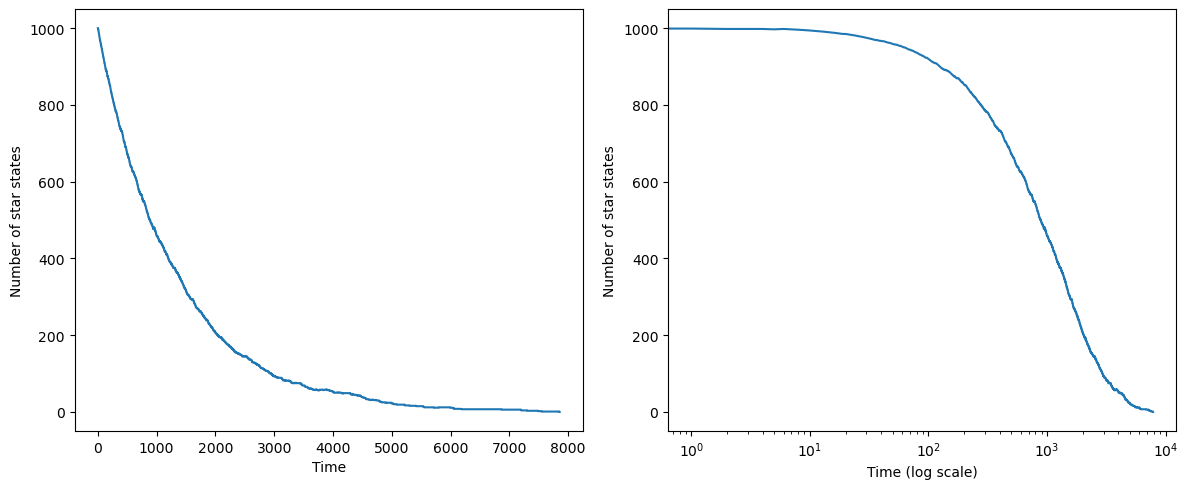

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(nb_star_state)
ax1.set_xlabel('Time')
ax1.set_ylabel('Number of star states')

ax2.plot(nb_star_state)
ax2.set_xscale('log')
ax2.set_xlabel('Time (log scale)')
ax2.set_ylabel('Number of star states')

plt.tight_layout()
plt.show()

# Coalescence times

In [26]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(np.float64(0.25541281188299536), np.float64(0.5493061443340548))

In [52]:
beta = 0.33
coup_type = 'gauss'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 3    
nb_itermax = 10**8
N_list = [100, 500, 1000, 5000, 10000, 50000, 100000]
csv_path = f"../results/tmp/coal_time_ER_{coup_type}_d{d}.csv"

In [53]:
df = compute_coal_time(N_list, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, init_mode='full_star', lazy=False)

N=100
Coalescence achieved at iteration 2931.
Coalescence achieved at iteration 12947.
Coalescence achieved at iteration 4223.
N=500
Coalescence achieved at iteration 36589.
Coalescence achieved at iteration 35909.
Coalescence achieved at iteration 76926.
N=1000
Coalescence achieved at iteration 924138.
Coalescence achieved at iteration 265245.
Coalescence achieved at iteration 234526.
N=5000
Coalescence achieved at iteration 3615956.
Coalescence achieved at iteration 2564219.
Coalescence achieved at iteration 3998636.
N=10000
Coalescence achieved at iteration 6834468.
Coalescence achieved at iteration 4909145.
Coalescence achieved at iteration 6227702.
N=50000
Coalescence achieved at iteration 44019191.
Coalescence achieved at iteration 34511867.
N=100000
Coalescence achieved at iteration 89538527.


In [54]:
if os.path.exists(csv_path):
    df_full = pd.read_csv(csv_path)
    df_combined = pd.concat([df_full, df], ignore_index=True)
    df_combined.to_csv(csv_path, index=False)
else:
    df.to_csv(csv_path, index=False)

In [55]:
df = pd.read_csv(csv_path)

print(df['beta'].unique())
print(df['sampler'].unique())
print(df['lazy'].unique())
print(df['init_mode'].unique())
print(df['n_runs'].unique())
print(df['max_iter'].unique())
print(df['N'].unique())
print(len(df))  # total number of rows

df

[0.31 0.29 0.33]
<StringArray>
['F_beta_Glauber']
Length: 1, dtype: str
[False]
<StringArray>
['full_star']
Length: 1, dtype: str
[3]
[100000000]
[   100    500   1000   5000  10000  50000 100000]
21


,beta,sampler,lazy,init_mode,n_runs,max_iter,N,n_coal,mean_coal_time,std_coal_time
0,0.31,F_beta_Glauber,False,full_star,3,100000000,100,3,3.905333e+03,1.668279e+03
1,0.31,F_beta_Glauber,False,full_star,3,100000000,500,3,4.563700e+04,1.529360e+04
2,0.31,F_beta_Glauber,False,full_star,3,100000000,1000,3,1.828513e+05,5.558215e+04
3,0.31,F_beta_Glauber,False,full_star,3,100000000,5000,3,9.097263e+05,2.413326e+05
4,0.31,F_beta_Glauber,False,full_star,3,100000000,10000,3,1.737095e+06,2.295755e+05
5,0.31,F_beta_Glauber,False,full_star,3,100000000,50000,3,1.420773e+07,3.350799e+05
6,0.31,F_beta_Glauber,False,full_star,3,100000000,100000,3,2.863307e+07,4.372536e+06
7,0.29,F_beta_Glauber,False,full_star,3,100000000,100,3,7.911000e+03,4.185553e+03
8,0.29,F_beta_Glauber,False,full_star,3,100000000,500,3,3.086867e+04,9.382779e+03
9,0.29,F_beta_Glauber,False,full_star,3,100000000,1000,3,6.104700e+04,1.966583e+04


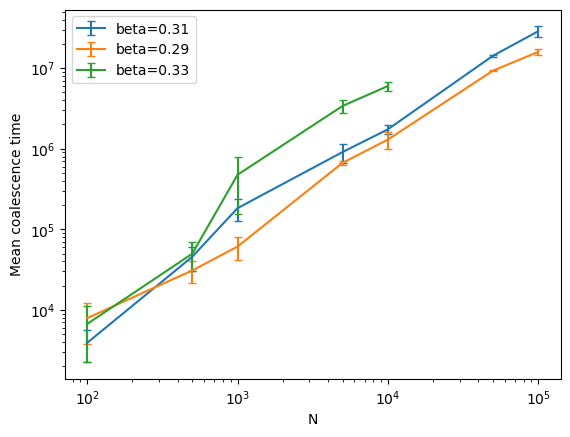

In [56]:
mask = (
    (df['sampler'] == 'F_beta_Glauber') &
    (df['lazy'] == False) &
    (df['init_mode'] == 'full_star') & 
    (df['n_coal'] == df['n_runs'])
)
df_filtered = df[mask]

betas_to_exclude = []
for beta in df_filtered['beta'].unique():
    if beta in betas_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['beta'] == beta]
    plt.errorbar(sub_df['N'], sub_df['mean_coal_time'],
                yerr=sub_df['std_coal_time'],
                label=f'beta={beta:.2f}',
                capsize=3)

plt.xlabel('N')
plt.ylabel('Mean coalescence time')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

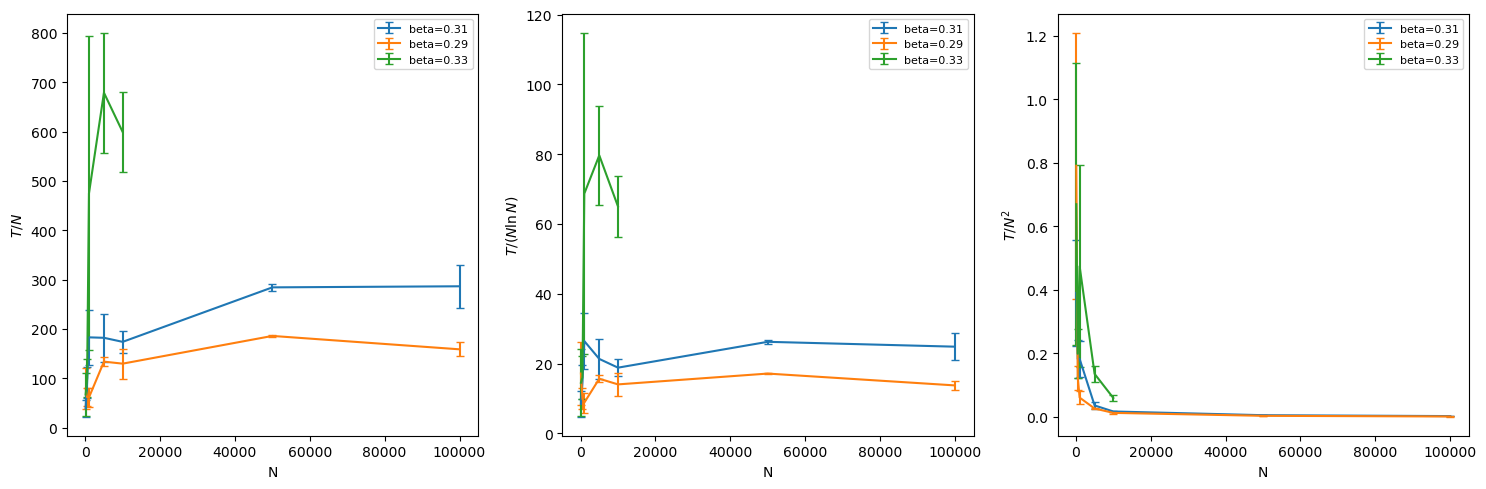

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
scalings = {
    r'$T / N$': (lambda N, T: T / N, 
                 lambda N, T, sT: sT / N),
    r'$T / (N \ln N)$': (lambda N, T: T / (N * np.log(N)), 
                          lambda N, T, sT: sT / (N * np.log(N))),
    r'$T / N^2$': (lambda N, T: T / N**2, 
                   lambda N, T, sT: sT / N**2),
}

for ax, (label, (scaling_fn, err_fn)) in zip(axes, scalings.items()):
    for beta in df_filtered['beta'].unique():
        sub_df = df_filtered[df_filtered['beta'] == beta].sort_values('N')
        N = sub_df['N'].values
        T = sub_df['mean_coal_time'].values
        sT = sub_df['std_coal_time'].values
        ax.errorbar(N, scaling_fn(N, T), yerr=err_fn(N, T, sT),
                    label=f'beta={beta:.2f}', capsize=3)
    ax.set_xlabel('N')
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

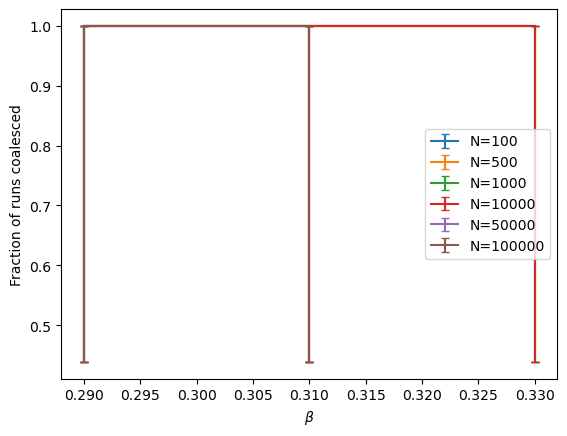

In [58]:
N_to_exclude = [5000]
for N in df_filtered['N'].unique():
    if N in N_to_exclude:
        continue    
    sub_df = df_filtered[df_filtered['N'] == N].sort_values('beta')
    k = sub_df['n_coal'].values
    n = sub_df['n_runs'].values
    p, err_down, err_up = wilson_interval(k, n)
    plt.errorbar(sub_df['beta'], p,
                 yerr=[err_down, err_up],
                 label=f'N={N}', capsize=3)

plt.xlabel(r'$\beta$')
plt.ylabel('Fraction of runs coalesced')
plt.legend()
plt.show()

# Evolution star states

In [59]:
d = 4
beta_SG = np.arctanh(np.sqrt(1/d))
beta_uni = np.arctanh(1/d)
beta_uni, beta_SG

(np.float64(0.25541281188299536), np.float64(0.5493061443340548))

In [66]:
N = 2000
beta_list = [0.2, 0.22, 0.23, 0.24, 0.25, 0.26, 0.27]
#beta_list = [0.3, 0.31, 0.32, 0.33, 0.34]
coup_type = 'ising'
G_builder = lambda N: create_ER_graph(N, d=4, coupling_type=coup_type)
nb_runs = 10    
nb_itermax = 10**7

In [67]:
dfs = []
for beta in beta_list:
    print(f"beta={beta}")
    df_beta = compute_nb_star(N, beta, G_builder, n_runs=nb_runs, sampler=F_beta_Glauber, max_iter=nb_itermax, init_mode='full_star', lazy=False, n_points=10000)
    dfs.append(df_beta)

df = pd.concat(dfs, ignore_index=True)

csv_path = f"../results/tmp/nb_star_ER_{coup_type}_d{d}_N{N}.csv"
df.to_csv(csv_path, index=False)


beta=0.2
Coalescence achieved at iteration 84742.


Coalescence achieved at iteration 93876.
Coalescence achieved at iteration 59013.
Coalescence achieved at iteration 66793.
Coalescence achieved at iteration 65327.
Coalescence achieved at iteration 99664.
Coalescence achieved at iteration 69714.
Coalescence achieved at iteration 66777.
Coalescence achieved at iteration 70224.
Coalescence achieved at iteration 56148.
beta=0.22
Coalescence achieved at iteration 111458.
Coalescence achieved at iteration 97369.
Coalescence achieved at iteration 102297.
Coalescence achieved at iteration 86986.
Coalescence achieved at iteration 92864.
Coalescence achieved at iteration 144734.
Coalescence achieved at iteration 194580.
Coalescence achieved at iteration 150452.
Coalescence achieved at iteration 135547.
Coalescence achieved at iteration 125294.
beta=0.23
Coalescence achieved at iteration 164056.
Coalescence achieved at iteration 92514.
Coalescence achieved at iteration 190443.
Coalescence achieved at iteration 307824.
Coalescence achieved at ite

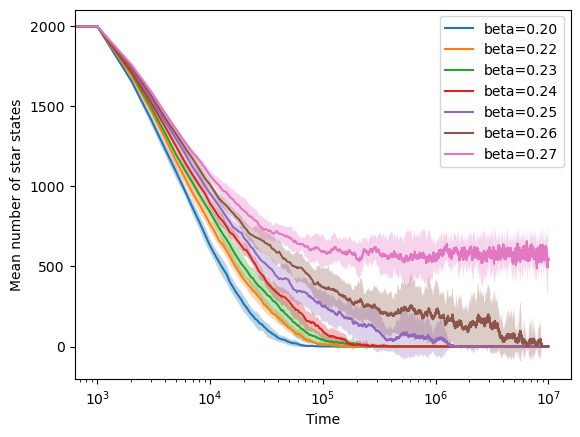

In [68]:
df = pd.read_csv(csv_path)
for beta in df['beta'].unique():
    sub_df = df[df['beta'] == beta].sort_values('time')
    plt.plot(sub_df['time'], sub_df['mean_nb_star'], label=f'beta={beta:.2f}')
    plt.fill_between(sub_df['time'],
                     sub_df['mean_nb_star'] - sub_df['std_nb_star'],
                     sub_df['mean_nb_star'] + sub_df['std_nb_star'],
                     alpha=0.3)
plt.xscale('log')
plt.xlabel('Time')
plt.ylabel('Mean number of star states')
plt.legend()
plt.show()

C = 0.039, R²=0.9415


/tmp/ipykernel_94771/1547148418.py:6: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)


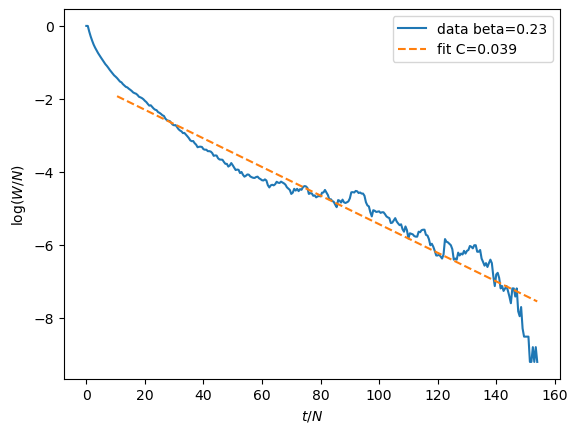

In [69]:
beta = 0.23
sub_df = df[df['beta'] == beta].sort_values('time')
N = sub_df['N'].values[0]

t_over_N = sub_df['time'].values / N
log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)

from scipy.stats import linregress

mask = (t_over_N > 10)  & (log_W_over_N > -np.inf) & np.isfinite(log_W_over_N)
slope, intercept, r, p, se = linregress(t_over_N[mask], log_W_over_N[mask])
C = -slope
print(f"C = {C:.3f}, R²={r**2:.4f}")

plt.plot(t_over_N, log_W_over_N, label=f'data beta={beta:.2f}')
plt.plot(t_over_N[mask], intercept + slope * t_over_N[mask], '--', label=f'fit C={C:.3f}')
plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend()
plt.show()

/tmp/ipykernel_94771/1150641705.py:7: RuntimeWarning: divide by zero encountered in log
  log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)


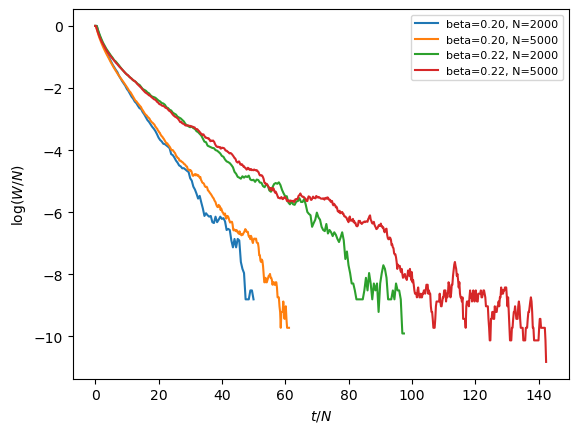

In [70]:
for beta in [0.2, 0.22]:
    for N in [2000, 5000]:
        csv_path = f"../results/tmp/nb_star_ER_{coup_type}_d{d}_N{N}.csv"
        df = pd.read_csv(csv_path)
        sub_df = df[(df['beta'] == beta) & (df['N'] == N)].sort_values('time')
        t_over_N = sub_df['time'].values / N
        log_W_over_N = np.log(sub_df['mean_nb_star'].values / N)
        plt.plot(t_over_N, log_W_over_N, label=f'beta={beta:.2f}, N={N}')

plt.xlabel(r'$t/N$')
plt.ylabel(r'$\log(W/N)$')
plt.legend(fontsize=8)
plt.show()